In [1]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, FunctionTransformer
from sklearn.feature_selection import mutual_info_classif
from sklearn.utils.class_weight import compute_class_weight

RANDOM_STATE = 42

## 1. Load DS1 and describe the data

**About the dataset**

| | |
|---|---|
| Source | [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/336/chronic+kidney+disease) |
| License | CC BY 4.0, use allowed with citation (Rubini et al., 2015) |
| Collection method | Hospital records from Apollo Hospitals, Karaikudi, India, collected over about 2 months and donated in 2015 (Rubini et al., 2015) |
| Size | 400 patients, 24 features, 1 target |
| Target | CKD (250) or not CKD (150) |

**Why this dataset**
- Real hospital data, used to check whether the weak signal in DS2 comes from the data or from our method
- Same first 24 features as DS2, so results can be compared directly
- Widely used benchmark for CKD prediction (Qin et al., 2020)
- Small and binary, so it supports objectives 1 and 2 but is limited for the MLP (objective 3)

In [2]:
path = "../../../../assets/datasets/1_UCI_Chronic_Kidney_Disease_Dataset/data/chronic_kidney_disease_full.arff"
text = Path(path).read_text()
attrs = re.findall(r"@attribute\s+'(\w+)'", text)
lines = text.split("@data")[1].strip().splitlines()

print("Rows with an extra comma:", sum(len(l.split(",")) != len(attrs) for l in lines))
print("Values with stray tabs or spaces:", sum(v != v.strip() for l in lines for v in l.split(",")))

Rows with an extra comma: 3
Values with stray tabs or spaces: 16


In [3]:
rows = [[v.strip() for v in l.split(",") if v != ""] for l in lines]
df = pd.DataFrame(rows, columns=attrs).replace("?", np.nan)

numeric = ["age", "bp", "sg", "al", "su", "bgr", "bu", "sc", "sod", "pot", "hemo", "pcv", "wbcc", "rbcc"]
df[numeric] = df[numeric].apply(pd.to_numeric)

df = df.rename(columns={
    "age": "Age", "bp": "Blood pressure (mm/Hg)", "sg": "Specific gravity", "al": "Albumin", "su": "Sugar",
    "rbc": "Red blood cells", "pc": "Pus cells", "pcc": "Pus cell clumps", "ba": "Bacteria",
    "bgr": "Blood glucose (mg/dl)", "bu": "Blood urea (mg/dl)", "sc": "Serum creatinine (mg/dl)",
    "sod": "Sodium (mEq/L)", "pot": "Potassium (mEq/L)", "hemo": "Hemoglobin (gms)", "pcv": "Packed cell volume",
    "wbcc": "White blood cell count", "rbcc": "Red blood cell count", "htn": "Hypertension", "dm": "Diabetes mellitus",
    "cad": "Coronary artery disease", "appet": "Appetite", "pe": "Pedal edema", "ane": "Anemia", "class": "Target",
})

overview = pd.Series({
    "Rows": df.shape[0],
    "Columns": df.shape[1],
    "Numeric columns": df.select_dtypes(include="number").shape[1],
    "Text columns": df.select_dtypes(exclude="number").shape[1],
    "Missing values": df.isnull().sum().sum(),
    "Rows with missing values": df.isnull().any(axis=1).sum(),
    "Duplicate rows": df.duplicated().sum(),
}, name="Value").to_frame()
display(overview)

,Value
Rows,400
Columns,25
Numeric columns,14
Text columns,11
Missing values,1012
Rows with missing values,242
Duplicate rows,0


In [4]:
columns = pd.DataFrame({
    "Type": df.dtypes.astype(str),
    "Missing": df.isnull().sum(),
    "Unique": df.nunique(),
    "Values / Range": [
        ", ".join(sorted(df[c].dropna().unique())) if df[c].dtype == "object"
        else f"{df[c].min():g} to {df[c].max():g}"
        for c in df.columns
    ],
})
display(columns)

,Type,Missing,Unique,Values / Range
Age,float64,9,76,2 to 90
Blood pressure (mm/Hg),float64,12,10,50 to 180
Specific gravity,float64,47,5,1.005 to 1.025
Albumin,float64,46,6,0 to 5
Sugar,float64,49,6,0 to 5
Red blood cells,object,152,2,"abnormal, normal"
Pus cells,object,65,2,"abnormal, normal"
Pus cell clumps,object,4,2,"notpresent, present"
Bacteria,object,4,2,"notpresent, present"
Blood glucose (mg/dl),float64,44,146,22 to 490


**Feature groups**

| Group | Features | Role |
|---|---|---|
| Kidney function (4) | serum creatinine, blood urea, albumin, specific gravity | Main CKD markers (KDIGO, 2024) |
| Blood tests (7) | hemoglobin, packed cell volume, red and white cell counts, sodium, potassium, glucose | CKD complications such as anemia |
| Urine tests (5) | sugar, red cells, pus cells, pus cell clumps, bacteria | Kidney damage |
| Medical history (6) | hypertension, diabetes, coronary artery disease, appetite, pedal edema, anemia | Known risk factors |
| Demographics (2) | age, blood pressure | Basic patient profile |

In [5]:
display(df.head())

,Age,Blood pressure (mm/Hg),Specific gravity,Albumin,Sugar,Red blood cells,Pus cells,Pus cell clumps,Bacteria,Blood glucose (mg/dl),...,Packed cell volume,White blood cell count,Red blood cell count,Hypertension,Diabetes mellitus,Coronary artery disease,Appetite,Pedal edema,Anemia,Target
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,ckd


**Observation:**
- 3 rows had an extra comma and 16 values had stray tabs or spaces; fixed when loading
- "?" marks a missing value; 60% of rows have at least one

## 2. Stratified train/test split

In [6]:
X = df.drop(columns=["Target"])
y = df["Target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

split = pd.DataFrame({
    "Rows": [len(X_train), len(X_test)],
    "Features": [X_train.shape[1], X_test.shape[1]],
}, index=["Train", "Test"])
display(split)

,Rows,Features
Train,320,24
Test,80,24


In [7]:
balance = pd.DataFrame({
    "Train %": y_train.value_counts(normalize=True).mul(100).round(1),
    "Test %": y_test.value_counts(normalize=True).mul(100).round(1),
})
display(balance)

,Train %,Test %
Target,,
ckd,62.5,62.5
notckd,37.5,37.5


**Observation:**
- 10 text features and a text Target, all need encoding
- Only 80 test rows, so the stratified split keeps the 62.5/37.5 class mix (Géron, 2022); models will also use cross-validation

## 3. Explore the training set

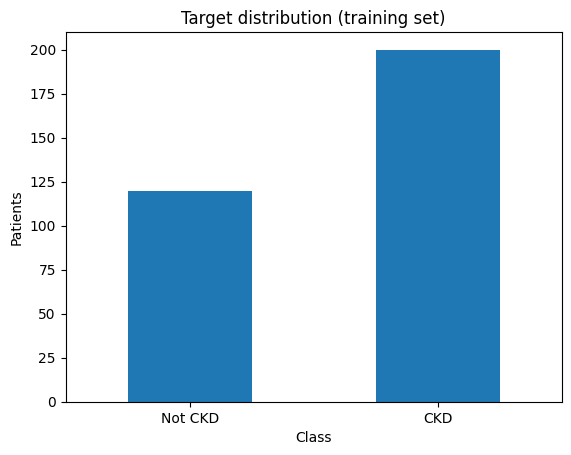

Imbalance ratio: 1.7


In [8]:
train = X_train.copy()
train["Target"] = y_train
order = ["notckd", "ckd"]
short = ["Not CKD", "CKD"]

counts = train["Target"].value_counts().reindex(order)
counts.set_axis(short).plot(kind="bar", title="Target distribution (training set)")
plt.xlabel("Class")
plt.ylabel("Patients")
plt.xticks(rotation=0)
plt.show()
print("Imbalance ratio:", round(counts.max() / counts.min(), 1))

In [9]:
num_cols = train.select_dtypes(include="number").columns
stats = train[num_cols].describe().T[["min", "max", "mean", "std"]]
stats["skew"] = train[num_cols].skew()
display(stats.round(3))

,min,max,mean,std,skew
Age,2.000,90.000,51.095,16.882,-0.614
Blood pressure (mm/Hg),50.000,140.000,76.323,12.722,0.698
Specific gravity,1.005,1.025,1.017,0.006,-0.158
Albumin,0.000,5.000,0.997,1.339,1.022
Sugar,0.000,5.000,0.482,1.142,2.360
Blood glucose (mg/dl),22.000,490.000,149.344,83.537,2.031
Blood urea (mg/dl),1.500,391.000,55.720,48.741,2.869
Serum creatinine (mg/dl),0.400,48.100,2.904,4.644,5.030
Sodium (mEq/L),104.000,163.000,137.774,7.222,-1.092
Potassium (mEq/L),2.500,47.000,4.655,3.562,10.509


In [10]:
text_cols = X_train.select_dtypes(exclude="number").columns
cat_stats = pd.DataFrame({
    "Values": [", ".join(X_train[c].value_counts().index) for c in text_cols],
    "Share %": [", ".join(X_train[c].value_counts(normalize=True).mul(100).round(1).astype(str)) for c in text_cols],
}, index=text_cols)
display(cat_stats)

,Values,Share %
Red blood cells,"normal, abnormal","79.8, 20.2"
Pus cells,"normal, abnormal","78.2, 21.8"
Pus cell clumps,"notpresent, present","89.9, 10.1"
Bacteria,"notpresent, present","94.6, 5.4"
Hypertension,"no, yes","65.3, 34.7"
Diabetes mellitus,"no, yes","67.2, 32.8"
Coronary artery disease,"no, yes","93.1, 6.9"
Appetite,"good, poor","79.3, 20.7"
Pedal edema,"no, yes","81.2, 18.8"
Anemia,"no, yes","86.8, 13.2"


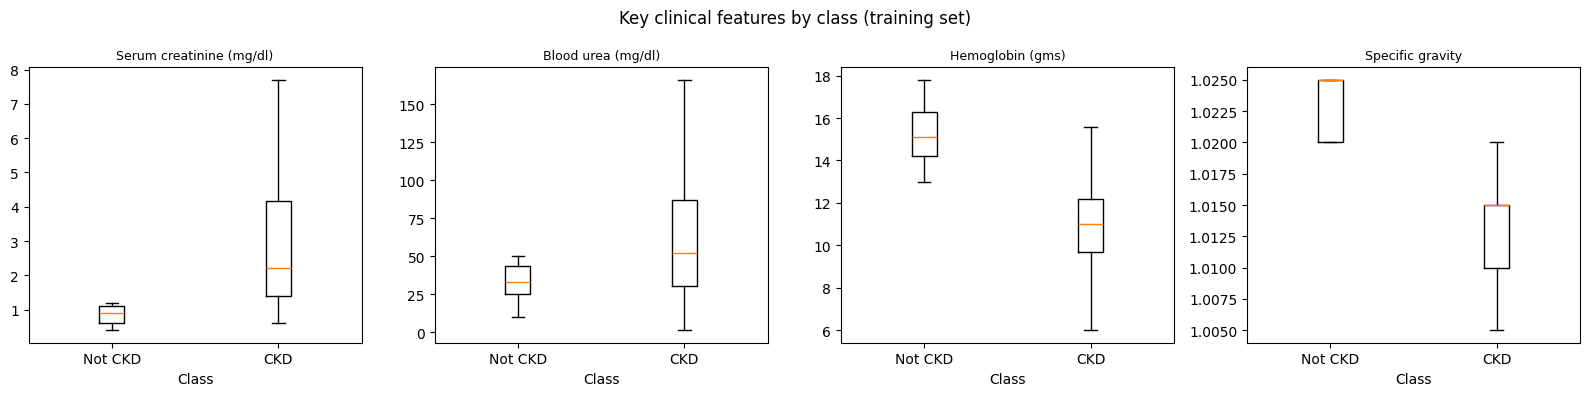

In [11]:
key = ["Serum creatinine (mg/dl)", "Blood urea (mg/dl)", "Hemoglobin (gms)", "Specific gravity"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, key):
    ax.boxplot([train.loc[train["Target"] == c, col].dropna() for c in order], tick_labels=short, showfliers=False)
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("Class")
fig.suptitle("Key clinical features by class (training set)")
fig.tight_layout()
plt.show()

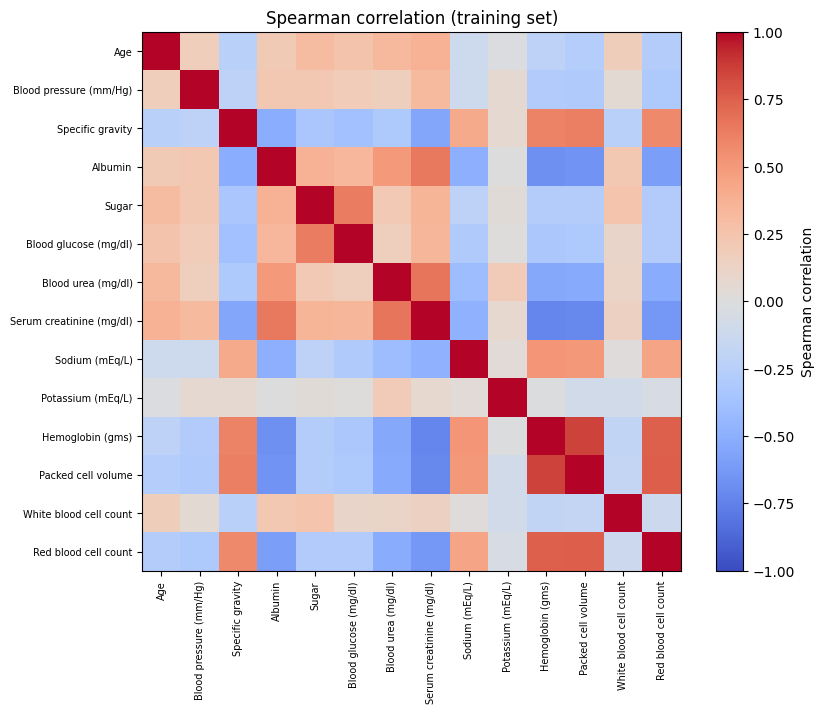

Largest correlation between two features: 0.857


In [12]:
corr = train[num_cols].corr(method="spearman")
plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Spearman correlation")
plt.xticks(range(len(num_cols)), num_cols, rotation=90, fontsize=7)
plt.yticks(range(len(num_cols)), num_cols, fontsize=7)
plt.title("Spearman correlation (training set)")
plt.show()

off = corr.where(~np.eye(len(corr), dtype=bool)).abs()
print("Largest correlation between two features:", round(off.max().max(), 3))

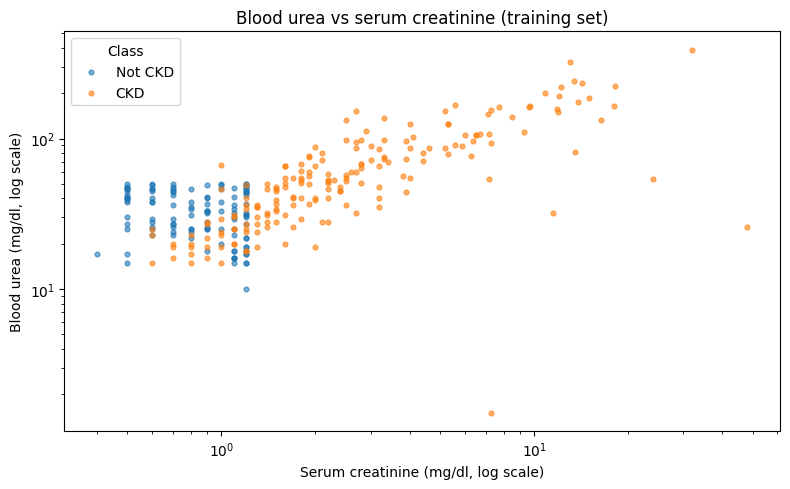

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
for c, s in zip(order, short):
    d = train[train["Target"] == c]
    ax.scatter(d["Serum creatinine (mg/dl)"], d["Blood urea (mg/dl)"], s=12, alpha=0.6, label=s)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Serum creatinine (mg/dl, log scale)")
ax.set_ylabel("Blood urea (mg/dl, log scale)")
ax.legend(title="Class")
ax.set_title("Blood urea vs serum creatinine (training set)")
fig.tight_layout()
plt.show()

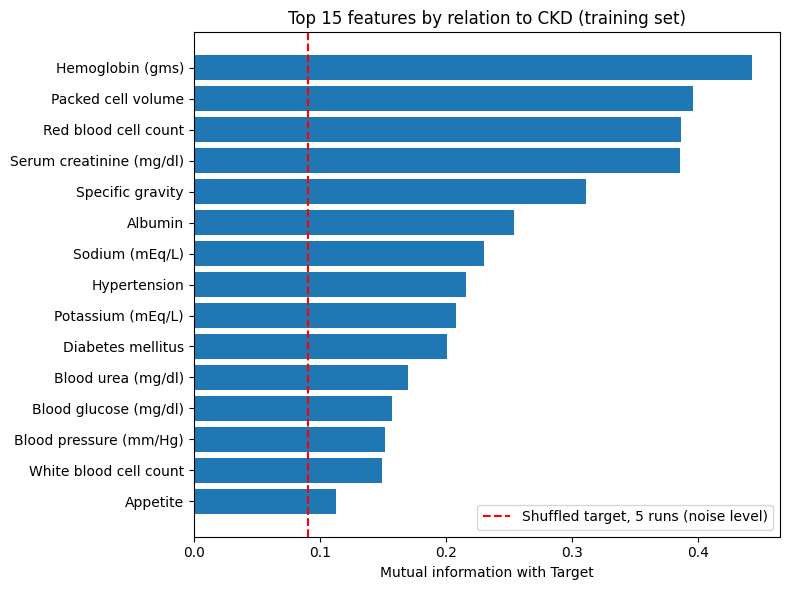

Features above noise: 17


In [14]:
filled = X_train.fillna(X_train.median(numeric_only=True)).fillna(X_train.mode().iloc[0])
codes = filled.apply(lambda c: c.astype("category").cat.codes if c.dtype == object else c)
is_cat = (X_train.dtypes == object).values
mi = pd.Series(mutual_info_classif(codes, y_train, discrete_features=is_cat, random_state=RANDOM_STATE), index=X_train.columns)
noise = max(
    mutual_info_classif(codes, y_train.sample(frac=1, random_state=s).values, discrete_features=is_cat, random_state=RANDOM_STATE).max()
    for s in range(5)
)

top = mi.sort_values().tail(15)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values)
ax.axvline(noise, color="red", linestyle="--", label="Shuffled target, 5 runs (noise level)")
ax.set_xlabel("Mutual information with Target")
ax.set_title("Top 15 features by relation to CKD (training set)")
ax.legend()
fig.tight_layout()
plt.show()
print("Features above noise:", (mi > noise).sum())

**Observation:**
- Mild imbalance (62.5% CKD, 37.5% not CKD)
- Creatinine, urea, glucose and white cell count are right-skewed, so they get a log transform in section 5
- Potassium up to 47 is impossible, which also explains its high skew; fixed in section 4
- CKD patients have higher creatinine and urea and lower hemoglobin and specific gravity
- Hemoglobin and packed cell volume are strongly correlated (0.86), as expected
- Urea rises with creatinine, as in real patients
- 17 of 24 features beat random noise (none did in DS2); hemoglobin, packed cell volume, red cell count and creatinine are strongest

## 4. Check missing values, duplicates and outliers

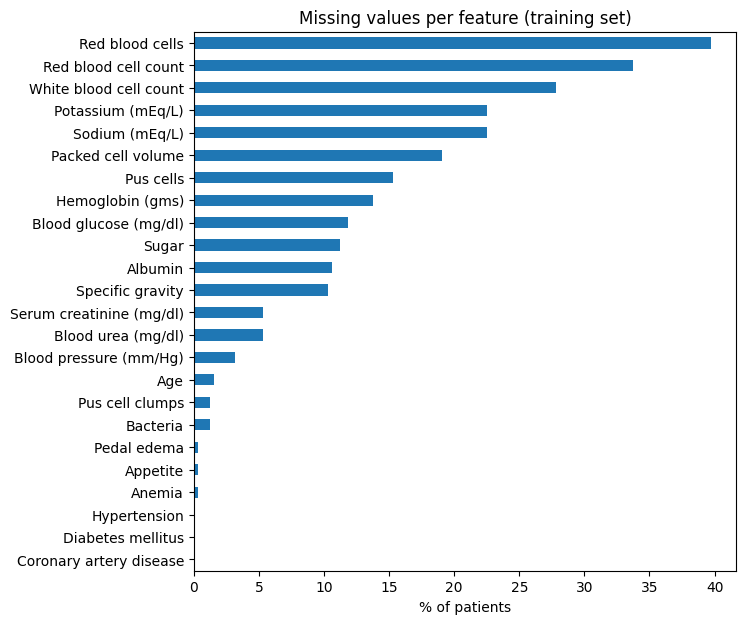

Duplicate rows: 0


In [15]:
missing = X_train.isnull().mean().mul(100).sort_values()
missing.plot(kind="barh", figsize=(7, 7), title="Missing values per feature (training set)")
plt.xlabel("% of patients")
plt.show()
print("Duplicate rows:", train.duplicated().sum())

In [16]:
q1 = train[num_cols].quantile(0.25)
q3 = train[num_cols].quantile(0.75)
iqr = q3 - q1
outliers = (train[num_cols] < q1 - 1.5 * iqr) | (train[num_cols] > q3 + 1.5 * iqr)
display(outliers.sum().sort_values(ascending=False).head(6).to_frame("Outliers (IQR)"))

,Outliers (IQR)
Sugar,52
Serum creatinine (mg/dl),39
Blood glucose (mg/dl),35
Blood urea (mg/dl),30
Blood pressure (mm/Hg),29
Sodium (mEq/L),12


In [17]:
for part in (X_train, X_test):
    print("Impossible values:", (part["Sodium (mEq/L)"] < 100).sum() + (part["Potassium (mEq/L)"] > 10).sum())
    part.loc[part["Sodium (mEq/L)"] < 100, "Sodium (mEq/L)"] = np.nan
    part.loc[part["Potassium (mEq/L)"] > 10, "Potassium (mEq/L)"] = np.nan

Impossible values: 2
Impossible values: 1


**Observation:**
- Up to 40% missing per feature; dropping rows would lose 60% of patients, so values are imputed in section 5
- No duplicates
- IQR outliers in sugar, creatinine, glucose and urea are kept, because very high values are expected in kidney failure (KDIGO, 2024)
- 3 impossible values (sodium 4.5, potassium 39 and 47), likely typing errors, set to missing

## 5. Impute, encode and scale

In [18]:
binary_cats = {
    "Red blood cells": ["normal", "abnormal"],
    "Pus cells": ["normal", "abnormal"],
    "Pus cell clumps": ["notpresent", "present"],
    "Bacteria": ["notpresent", "present"],
    "Hypertension": ["no", "yes"],
    "Diabetes mellitus": ["no", "yes"],
    "Coronary artery disease": ["no", "yes"],
    "Appetite": ["good", "poor"],
    "Pedal edema": ["no", "yes"],
    "Anemia": ["no", "yes"],
}

ordinal_nums = ["Specific gravity", "Albumin", "Sugar"]
skewed = [c for c in num_cols if c not in ordinal_nums and X_train[c].skew() > 1]
other_num = [c for c in num_cols if c not in skewed]
print("Log-transformed:", skewed)

preprocess = ColumnTransformer([
    ("log", make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()), skewed),
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), other_num),
    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"), OrdinalEncoder(categories=list(binary_cats.values()))), list(binary_cats)),
], verbose_feature_names_out=False).set_output(transform="pandas")

X_train_prep = preprocess.fit_transform(X_train)
X_test_prep = preprocess.transform(X_test)

target_map = {name: i for i, name in enumerate(order)}
y_train_enc = y_train.map(target_map)
y_test_enc = y_test.map(target_map)

print(X_train_prep.shape, X_test_prep.shape, "missing after:", X_train_prep.isnull().sum().sum())
display(X_train_prep.head())

Log-transformed: ['Blood glucose (mg/dl)', 'Blood urea (mg/dl)', 'Serum creatinine (mg/dl)', 'White blood cell count']
(320, 24) (80, 24) missing after: 0


,Blood glucose (mg/dl),Blood urea (mg/dl),Serum creatinine (mg/dl),White blood cell count,Age,Blood pressure (mm/Hg),Specific gravity,Albumin,Sugar,Sodium (mEq/L),...,Red blood cells,Pus cells,Pus cell clumps,Bacteria,Hypertension,Diabetes mellitus,Coronary artery disease,Appetite,Pedal edema,Anemia
380,-0.366492,-0.950125,-0.505884,-0.687628,0.469875,-1.313179,0.412298,-0.684861,-0.394777,0.185176,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
56,-0.223696,2.031924,2.092884,1.240055,1.486223,-0.514287,-0.503920,1.622039,3.293647,-1.075595,...,0.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0
126,0.209884,1.614811,0.878642,0.122234,1.127512,1.083498,-0.503920,-0.684861,-0.394777,-0.287613,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0
371,-1.215166,0.215804,-1.042892,-0.687628,-1.383468,-1.313179,1.328515,-0.684861,-0.394777,1.130754,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
333,-0.680465,0.089465,-0.431639,-2.127836,-1.682394,0.284605,0.412298,-0.684861,-0.394777,0.657965,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


**Observation:**
- Missing values filled with the training median (numeric) or most frequent value (text), fitted on train only (Géron, 2022)
- Right-skewed features log-transformed, then all numeric features scaled (mean 0, std 1) for kNN and the MLP
- Specific gravity, albumin and sugar are graded scales, kept numeric without a log transform
- Binary text features encoded 0/1 (abnormal, present, poor or yes = 1); Target encoded 0 not CKD, 1 CKD
- No missing values remain

## 6. Class imbalance

In [19]:
weights = compute_class_weight("balanced", classes=np.arange(len(order)), y=y_train_enc)
display(pd.DataFrame({"Weight": weights.round(2)}, index=order))

,Weight
notckd,1.33
ckd,0.80


**Observation:**
- Not CKD gets weight 1.33, CKD 0.80
- Imbalance is mild, but weights keep both classes equal for macro-F1

## 7. Save the processed data

In [20]:
out = Path("../../../../assets/datasets/1_UCI_Chronic_Kidney_Disease_Dataset/processed")
out.mkdir(exist_ok=True)

X_train_prep.assign(Target=y_train_enc).to_csv(out / "train.csv", index=False)
X_test_prep.assign(Target=y_test_enc).to_csv(out / "test.csv", index=False)

**Observation:**
- All model notebooks use these files, so every model sees the same data

## References

| Reference | Link | How I used it |
|---|---|---|
| Anthropic (2026) *Claude Opus 5.5* | [link](https://claude.ai) | GenAI policy, Framework statement 6: I used it to generate the code, then evaluated the code myself. It also drafted the markdown text, which I will rewrite in my own words |
| Géron, A. (2022) *Hands-On Machine Learning*, 3rd edn. O'Reilly | [link](https://www.oreilly.com/library/view/hands-on-machine-learning/9781098125967/) | Workflow I followed: stratified split, imputing, log transform, fitting on train only (sections 2 to 5) |
| KDIGO (2024) CKD Guideline. *Kidney International*, 105(4S) | [link](https://doi.org/10.1016/j.kint.2023.10.018) | Kidney markers (section 1); why I kept extreme values (section 4) |
| Qin, J. et al. (2020) *A Machine Learning Methodology for Diagnosing CKD*. IEEE Access, 8 | [link](https://doi.org/10.1109/ACCESS.2019.2963053) | Related work: models on the UCI dataset reach near-perfect accuracy (section 1) |
| Rubini, L. et al. (2015) *Chronic Kidney Disease*. UCI | [link](https://doi.org/10.24432/C5G020) | Source, license and collection method of DS1 (section 1) |